In [18]:
from IPython.utils import io
import warnings

with io.capture_output() as captured:
    warnings.filterwarnings("ignore")
    from anlffr.helper import biosemi2mne as bs
    import mne
    import fnmatch
    import os
    from anlffr.preproc import find_blinks
    from mne.preprocessing.ssp import compute_proj_epochs
    from mne import concatenate_epochs
    from scipy import io
    import pylab as pl
    import numpy as np

mne.set_log_level('ERROR')
warnings.filterwarnings("ignore")

In [19]:
fpath = '/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/'
subj = 'HR'
bdfs = fnmatch.filter(os.listdir(fpath), subj + '_Att*.bdf')
print(bdfs)
removeblinks = True

['HR_Attention+006.bdf', 'HR_Attention+007.bdf', 'HR_Attention+005.bdf', 'HR_Attention+004.bdf', 'HR_Attention+001.bdf', 'HR_Attention+003.bdf', 'HR_Attention+002.bdf', 'HR_Attention.bdf', 'HR_Attention+008.bdf']


In [22]:
bdfs = ['HR_Attention.bdf', 'HR_Attention+004.bdf', 'HR_Attention+001.bdf', 'HR_Attention+003.bdf', 'HR_Attention+002.bdf']

In [23]:
leads = []
lags = []
lefts = []
rights = []

for k, bdf in enumerate(bdfs):
    print(k, bdf)
    edfname = os.path.join(fpath, bdf)
    raw, eves = bs.importbdf(edfname, hptsname='biosemi10_20.hpts')

    channels_to_drop = ['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp']
    # raw.drop_channels(channels_to_drop)

    raw.info['bads'] += ['EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8']

    raw.filter(l_freq=1., h_freq=40.)


    if k==0:
        blinks = find_blinks(raw, ch_name=['Fp1', ])
        epochs_blinks = mne.Epochs(raw, blinks, 998, tmin=-0.25,tmax=0.25, proj=True, baseline=(-0.25, 0), reject=dict(eeg=1000e-6))
        blink_projs = compute_proj_epochs(epochs_blinks, n_eeg=2, verbose='DEBUG')
    
    # raw.plot_projs_topomap()
    raw.add_proj(blink_projs)
    # raw.del_proj(1)
    raw.apply_proj()

    tmin, tmax = -0.2, 5.0
    baseline=(-0.2, 0.)
    rejthresh = 200e-6

    events_left = [7,8]
    events_right = [9,10]
    events_lead = [7,9]
    events_lag = [8,10]

    epochs_lead = mne.Epochs(raw, eves, event_id=events_lead, baseline=baseline, proj=True,
                        tmin=tmin, tmax=tmax, reject=dict(eeg=rejthresh))
    epochs_lag = mne.Epochs(raw, eves, event_id=events_lag, baseline=baseline, proj=True,
                        tmin=tmin, tmax=5, reject=dict(eeg=rejthresh))
    epochs_left = mne.Epochs(raw, eves, event_id=events_left, baseline=baseline, proj=True,
                        tmin=tmin, tmax=5, reject=dict(eeg=rejthresh))
    epochs_rigth = mne.Epochs(raw, eves, event_id=events_right, baseline=baseline, proj=True,
                              tmin=tmin, tmax=5, reject=dict(eeg=rejthresh))

    leads += [epochs_lead, ]
    lags += [epochs_lag, ]
    lefts += [epochs_left, ]
    rights += [epochs_rigth, ]

lead = concatenate_epochs(leads)
lag = concatenate_epochs(lags)
left = concatenate_epochs(lefts)
right = concatenate_epochs(rights)

0 HR_Attention.bdf
Re-referencing data to: EXG1 EXG2Got 1 parallel jobs after requesting None
    Getting epoch for 44358-52551
    Rejecting  epoch based on EEG : ['AF3', 'FC1', 'T7', 'CP5', 'PO3', 'O1', 'O2', 'P8', 'C4', 'FC6', 'FC2', 'F8', 'AF4', 'Fp2']
    Getting epoch for 55616-63809
    Getting epoch for 68564-76757
    Getting epoch for 110558-118751
    Getting epoch for 122280-130473
    Getting epoch for 145568-153761
    Getting epoch for 152677-160870
    Getting epoch for 163367-171560
    Getting epoch for 171600-179793
    Getting epoch for 181173-189366
    Getting epoch for 202442-210635
    Getting epoch for 214308-222501
    Getting epoch for 223183-231376
    Getting epoch for 260660-268853
    Getting epoch for 317387-325580
    Getting epoch for 340322-348515
    Getting epoch for 357370-365563
    Getting epoch for 395338-403531
    Getting epoch for 405597-413790
    Getting epoch for 413093-421286
    Getting epoch for 426900-435093
    Getting epoch for 43296

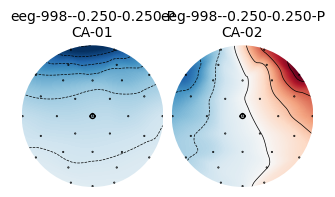

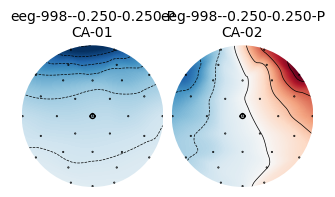

In [24]:
raw.plot_projs_topomap()

In [25]:
left_unevo = left.subtract_evoked()
right_unevo = right.subtract_evoked()

In [26]:
freqs = np.arange(20, 50, 1)
n_cycles = freqs * 0.5
method = 'multitaper'

power_left = left_unevo.compute_tfr(method=method, freqs=freqs, n_cycles=n_cycles, average=True)
power_right = right_unevo.compute_tfr(method=method, freqs=freqs, n_cycles=n_cycles, average=True)

In [27]:
# power_left.plot(baseline=[-0.2, 0.], mode='logratio')

In [28]:
power_left.data.shape

(32, 30, 85198)

In [29]:
# power_right.plot(baseline=[-0.2, 0.], mode='logratio')

In [30]:
power_left_baseline = power_left.apply_baseline(baseline=(-0.2, 0), mode='ratio')
power_right_baseline = power_right.apply_baseline(baseline=(-0.2,0), mode='ratio')

power_left_baseline = power_left_baseline.crop(tmin=2.0, tmax=4.5)
power_right_baseline = power_right_baseline.crop(tmin=2.0, tmax=4.5)

In [31]:
power_left_baseline.crop(fmin=27, fmax=35)
power_right_baseline.crop(fmin=27, fmax=35)

Data type,Average Power Estimates
Data source,Epochs
Number of epochs,32
Dims,"channel, freq, time"
Estimation method,multitaper
Number of channels,32
Number of timepoints,40961
Number of frequency bins,9
Frequency range,27.00 – 35.00 Hz


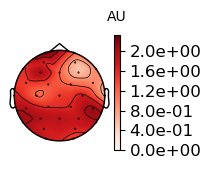

In [32]:
# from matplotlib import pyplot as plt
power_right_baseline.plot_topomap(tmin=3, tmax=4, fmin=30, fmax=45, sphere='eeglab')
pl.show()

In [ ]:
power_right_baseline.data.shape
avg_power_right_baseline = power_right_baseline.data.mean(axis=(1,2))
avg_power_left_baseline = power_left_baseline.data.mean(axis=(1,2))


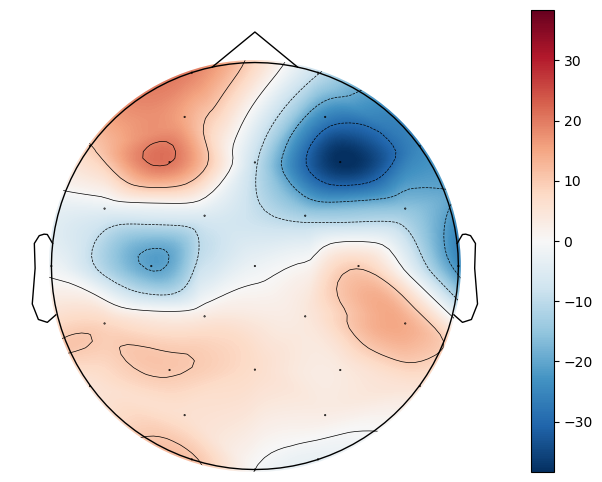

In [34]:
power_right_left = ((avg_power_right_baseline - avg_power_left_baseline)/ ((avg_power_right_baseline + avg_power_left_baseline)*0.5))*100

channels = ['Fp1','AF3','F7','F3','FC1','FC5','T7','C3','CP1','CP5','P7','P3','Pz','PO3',
                    'O1','Oz','O2','PO4','P4','P8','CP6','CP2','C4','T8','FC6','FC2','F4','F8','AF4','Fp2','Fz','Cz']
info_picked = mne.pick_info(left.info, mne.pick_channels(left.info['ch_names'], include =channels))

fig, ax = pl.subplots(figsize=(8, 6))
im,_ = mne.viz.plot_topomap(power_right_left, info_picked, sphere='eeglab', axes=ax, ch_type='eeg',show=False)
pl.colorbar(im, ax=ax)
pl.show()
